In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(r"C:\Users\HP\auspify-ml-internship\data\netflix_clean.csv")
print(df.shape, "| duplicate titles:", df["title"].duplicated().sum())

def tokens(text):
    # "Dramas, International Movies" -> "Dramas International_Movies"
    return " ".join(t.strip().replace(" ", "_") for t in str(text).split(","))

df["genres_tok"] = df["listed_in"].apply(tokens)
df["director_tok"] = df["director"].apply(lambda d: "" if d == "Unknown" else tokens(d))
df["country_tok"] = df["country"].apply(lambda c: "" if c == "Unknown" else tokens(c))

df["soup"] = (
    df["type"].str.replace(" ", "_") + " "
    + df["genres_tok"] + " "
    + df["director_tok"] + " "
    + df["country_tok"] + " "
    + df["rating"]
)

df[["title", "soup"]].head(5)

(8790, 14) | duplicate titles: 3


,title,soup
0,Dick Johnson Is Dead,Movie Documentaries Kirsten_Johnson United_Sta...
1,Ganglands,TV_Show Crime_TV_Shows International_TV_Shows ...
2,Midnight Mass,TV_Show TV_Dramas TV_Horror TV_Mysteries Mike_...
3,Confessions of an Invisible Girl,Movie Children_&_Family_Movies Comedies Bruno_...
4,Sankofa,Movie Dramas Independent_Movies International_...


In [2]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(token_pattern=r"\S+", lowercase=True)
tfidf_matrix = tfidf.fit_transform(df["soup"])

print(tfidf_matrix.shape)
print(tfidf.get_feature_names_out()[:15])
print(df[df["title"].duplicated(keep=False)][["title", "type", "release_year"]])

(8790, 5130)
['a._l._vijay' 'a._raajdheep' 'a._salaam' 'a.r._murugadoss'
 'aadish_keluskar' 'aamir_bashir' 'aamir_khan' 'aanand_rai' 'aaron_burns'
 'aaron_hancox' 'aaron_hann' 'aaron_lieber' 'aaron_moorhead' 'aaron_nee'
 'aaron_sorkin']
       title     type  release_year
393    9-Feb  TV Show          2018
537    9-Feb  TV Show          2018
2925  15-Aug    Movie          2019
3285  22-Jul    Movie          2018
4260  22-Jul    Movie          2018
4261  15-Aug    Movie          2019


In [3]:
from sklearn.metrics.pairwise import cosine_similarity

# row position of one title (first match if duplicated)
idx = df.index[df["title"] == "Ganglands"][0]

# similarity of this title against every title
sims = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).flatten()

# top 6 positions (the first is the title itself)
top = sims.argsort()[::-1][:6]
print(pd.DataFrame({
    "title": df.loc[top, "title"].values,
    "type": df.loc[top, "type"].values,
    "similarity": sims[top].round(3),
}))

             title     type  similarity
0        Ganglands  TV Show       1.000
1       Sentinelle    Movie       0.733
2  Earth and Blood    Movie       0.725
3            Lupin  TV Show       0.716
4       Crime Time  TV Show       0.716
5    La Révolution  TV Show       0.590


In [4]:
print(df.loc[top, ["title", "director", "country", "listed_in"]])

                title         director country  \
1           Ganglands  Julien Leclercq  France   
1183       Sentinelle  Julien Leclercq  France   
2142  Earth and Blood  Julien Leclercq  France   
6738            Lupin          Unknown  France   
8408       Crime Time          Unknown  France   
7036    La Révolution          Unknown  France   

                                              listed_in  
1     Crime TV Shows, International TV Shows, TV Act...  
1183   Action & Adventure, Dramas, International Movies  
2142            Dramas, International Movies, Thrillers  
6738  Crime TV Shows, International TV Shows, TV Act...  
8408  Crime TV Shows, International TV Shows, TV Act...  
7036  International TV Shows, TV Action & Adventure,...  


In [5]:
def recommend(title, n=5):
    matches = df.index[df["title"].str.lower() == title.lower()]
    if len(matches) == 0:
        return f"Title '{title}' not found."
    idx = matches[0]

    sims = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).flatten()
    sims[idx] = -1                      # exclude the title itself
    top = sims.argsort()[::-1][:n]

    return pd.DataFrame({
        "title": df.loc[top, "title"].values,
        "type": df.loc[top, "type"].values,
        "genres": df.loc[top, "listed_in"].values,
        "similarity": sims[top].round(3),
    })

recommend("Ganglands")

,title,type,genres,similarity
0,Sentinelle,Movie,"Action & Adventure, Dramas, International Movies",0.733
1,Earth and Blood,Movie,"Dramas, International Movies, Thrillers",0.725
2,Lupin,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.716
3,Crime Time,TV Show,"Crime TV Shows, International TV Shows, TV Act...",0.716
4,La Révolution,TV Show,"International TV Shows, TV Action & Adventure,...",0.590


In [8]:
recommend("Midnight Mass", n=5)

,title,type,genres,similarity
0,The Haunting of Hill House,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.742
1,Brand New Cherry Flavor,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.742
2,The Haunting of Bly Manor,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.742
3,Ratched,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.742
4,The Originals,TV Show,"TV Dramas, TV Horror, TV Mysteries",0.701


In [9]:
df[df["listed_in"].str.contains("Kids")][["title", "type"]].sample(5)

,title,type
6948,Hilda,TV Show
191,Alien TV,TV Show
8205,Buddy Thunderstruck,TV Show
20,True: Magical Friends,TV Show
8302,Turbo FAST,TV Show


In [10]:
df["genre_set"] = df["listed_in"].apply(lambda s: set(s.split(", ")))

def genre_overlap(idx, rec_idx):
    base = df.at[idx, "genre_set"]
    return np.mean([len(base & df.at[j, "genre_set"]) > 0 for j in rec_idx])

rng = np.random.default_rng(42)
sample = rng.choice(len(df), size=500, replace=False)

model_scores, random_scores = [], []
for idx in sample:
    sims = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).flatten()
    sims[idx] = -1
    top = sims.argsort()[::-1][:5]
    model_scores.append(genre_overlap(idx, top))

    others = np.delete(np.arange(len(df)), idx)
    random_scores.append(genre_overlap(idx, rng.choice(others, size=5, replace=False)))

print("Recommender:", round(np.mean(model_scores), 3))
print("Random     :", round(np.mean(random_scores), 3))

Recommender: 0.919
Random     : 0.254


In [11]:
# profile without genres
df["soup_nogenre"] = (
    df["type"].str.replace(" ", "_") + " "
    + df["director_tok"] + " "
    + df["country_tok"] + " "
    + df["rating"]
)
tfidf_ng = TfidfVectorizer(token_pattern=r"\S+", lowercase=True)
matrix_ng = tfidf_ng.fit_transform(df["soup_nogenre"])

ng_scores = []
for idx in sample:
    sims = cosine_similarity(matrix_ng[idx], matrix_ng).flatten()
    sims[idx] = -1
    top = sims.argsort()[::-1][:5]
    ng_scores.append(genre_overlap(idx, top))

print("Full profile      :", round(np.mean(model_scores), 3))
print("Without genres    :", round(np.mean(ng_scores), 3))
print("Random            :", round(np.mean(random_scores), 3))

Full profile      : 0.919
Without genres    : 0.504
Random            : 0.254


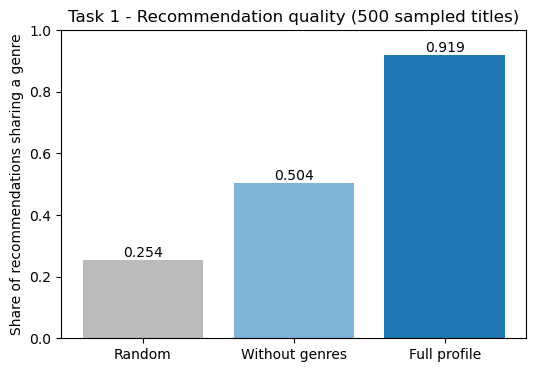

In [12]:
import matplotlib.pyplot as plt

labels = ["Random", "Without genres", "Full profile"]
values = [np.mean(random_scores), np.mean(ng_scores), np.mean(model_scores)]

plt.figure(figsize=(6, 4))
bars = plt.bar(labels, values, color=["#bbbbbb", "#7fb3d5", "#1f77b4"])
for b, v in zip(bars, values):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.3f}", ha="center")
plt.ylim(0, 1)
plt.ylabel("Share of recommendations sharing a genre")
plt.title("Task 1 - Recommendation quality (500 sampled titles)")
plt.savefig("../outputs/task1_recommendation_quality.png", dpi=150, bbox_inches="tight")
plt.show()